# 06 · Comparación de los tres modelos de agrupamiento

**Objetivo específico 1 del protocolo:** *comparar el desempeño de tres algoritmos de agrupamiento mediante métricas de evaluación*.

**Entradas:** decisiones del notebook 05 (`outputs/reports/05_decisiones.json`) y la representación elegida (**R4b**: 10 variables que incluyen los 12 delitos, con los tres delitos sexuales agravados sumados en un indicador).

## Plan

1. Evaluar cada algoritmo con $k = 2$ a $10$: Silhouette, Davies-Bouldin, Calinski-Harabasz y estabilidad bootstrap.
2. Aplicar el **criterio propio de cada algoritmo** para elegir $k$: codo y estadístico gap (K-means), BIC y certeza de asignación (GMM), *eigengap* (Spectral).
3. Elegir $k$ para cada algoritmo con una **regla común** y explícita, igual para los tres.
4. Comparar los tres modelos en su $k$ elegido y seleccionar el **modelo ganador**.

## 0. Configuración

In [1]:
import sys
import json
import warnings
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.csgraph import laplacian
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import kneighbors_graph
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples
from IPython.display import display

from src.utilidades import (RUTA_PROCESSED, RAIZ as RAIZ_PROY, COLOR, PALETA_CATEGORICA,
                            configurar_estilo, subtitulo, fuente, guardar_figura)
from src.modelos import (metricas_internas, estabilidad_bootstrap, ordenar_grupos,
                         estadistico_gap)

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de grafo no conexo en Spectral
configurar_estilo()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

CARPETA_FIG = "06_comparacion"
FUENTE = "Fuente: elaboración propia con datos del MP (denuncias) e INE (población)."
RUTA_REPORTES = RAIZ_PROY / "outputs" / "reports"

with open(RUTA_REPORTES / "05_decisiones.json", encoding="utf-8") as f:
    decisiones = json.load(f)
SEMILLA = decisiones["semilla"]
ALGORITMOS = decisiones["algoritmos"]
X_df = pd.read_csv(RUTA_PROCESSED / "matrices" / f"{decisiones['representacion']}.csv",
                   index_col=0, encoding="utf-8-sig")
X = X_df.values
RANGO_K = range(2, 11)
N_BOOT = 50
UMBRAL_ESTABLE = 0.75     # Hennig (2008): ARI ≥ 0.75 indica un grupo/partición estable
COLOR_ALG = dict(zip(ALGORITMOS, PALETA_CATEGORICA))

print(f"Representación: {decisiones['representacion']}  ({X.shape[0]} municipios × {X.shape[1]} variables)")
print(f"Algoritmos: {ALGORITMOS}")
print("Variables:", ", ".join(X_df.columns))

Representación: R4b_agravados_agrupados  (340 municipios × 10 variables)
Algoritmos: ['K-means', 'GMM (diag)', 'Spectral']
Variables: homicidio, asesinato, robo, robo_agravado, hurto, hurto_agravado, extorsion, violacion, agresion_sexual, sexuales_agravados


In [2]:
def constructor(algoritmo, k):
    """Devuelve una función X -> etiquetas con la configuración del notebook 05."""
    if algoritmo == "K-means":
        return lambda Z: KMeans(k, n_init=20, random_state=SEMILLA).fit_predict(Z)
    if algoritmo == "GMM (diag)":
        return lambda Z: GaussianMixture(k, covariance_type="diag", n_init=5,
                                         random_state=SEMILLA).fit_predict(Z)
    if algoritmo == "Spectral":
        return lambda Z: SpectralClustering(k, affinity="nearest_neighbors", n_neighbors=10,
                                            random_state=SEMILLA).fit_predict(Z)
    raise ValueError(algoritmo)

## 1. Barrido de $k$ = 2 a 10

Para cada algoritmo y cada $k$ se calculan las tres métricas internas y la estabilidad con **50 remuestreos bootstrap**. Según Hennig (2008), un ARI medio ≥ 0.75 indica una partición **estable**; entre 0.6 y 0.75, que refleja patrones pero es sensible a los datos; y por debajo de 0.6, que es **inestable**.

In [3]:
filas = []
for alg in ALGORITMOS:
    for k in RANGO_K:
        ajustar = constructor(alg, k)
        m = metricas_internas(X, ajustar(X))
        est, est_sd = estabilidad_bootstrap(ajustar, X, n_boot=N_BOOT, semilla=SEMILLA)
        filas.append({"algoritmo": alg, **m, "k": k, "estabilidad": est, "estabilidad_sd": est_sd})
barrido = pd.DataFrame(filas)
barrido.to_csv(RUTA_REPORTES / "06_barrido_k.csv", index=False, encoding="utf-8-sig")

for col in ["silhouette", "davies_bouldin", "calinski_harabasz", "estabilidad", "n_grupo_menor"]:
    print(col)
    display(barrido.pivot_table(index="k", columns="algoritmo", values=col)[ALGORITMOS])

silhouette


algoritmo,K-means,GMM (diag),Spectral
k,,,
2,0.306,0.302,0.305
3,0.232,0.228,0.232
4,0.213,0.161,0.208
5,0.175,0.164,0.169
6,0.154,0.133,0.146
7,0.145,0.128,0.137
8,0.146,0.109,0.131
9,0.143,0.100,0.137
10,0.145,0.095,0.126


davies_bouldin


algoritmo,K-means,GMM (diag),Spectral
k,,,
2,1.217,1.233,1.196
3,1.388,1.399,1.268
4,1.641,1.831,1.625
5,1.611,1.676,1.660
6,1.721,1.955,1.672
7,1.811,1.862,1.829
8,1.704,2.004,1.839
9,1.824,2.105,1.790
10,1.687,2.046,1.732


calinski_harabasz


algoritmo,K-means,GMM (diag),Spectral
k,,,
2,206.719,203.624,190.122
3,167.557,165.248,157.261
4,133.004,126.803,125.739
5,115.536,110.765,109.833
6,100.697,93.620,93.859
7,90.487,83.328,84.412
8,82.918,71.985,78.213
9,77.180,67.027,70.943
10,72.792,63.496,65.188


estabilidad


algoritmo,K-means,GMM (diag),Spectral
k,,,
2,0.814,0.809,0.654
3,0.914,0.873,0.869
4,0.612,0.775,0.565
5,0.798,0.807,0.613
6,0.623,0.602,0.581
7,0.575,0.563,0.563
8,0.543,0.538,0.534
9,0.523,0.494,0.500
10,0.511,0.519,0.474


n_grupo_menor


algoritmo,K-means,GMM (diag),Spectral
k,,,
2,139.000,142.000,113.000
3,88.000,88.000,67.000
4,59.000,60.000,47.000
5,42.000,40.000,43.000
6,34.000,34.000,18.000
7,31.000,20.000,24.000
8,27.000,17.000,18.000
9,23.000,9.000,12.000
10,14.000,14.000,12.000


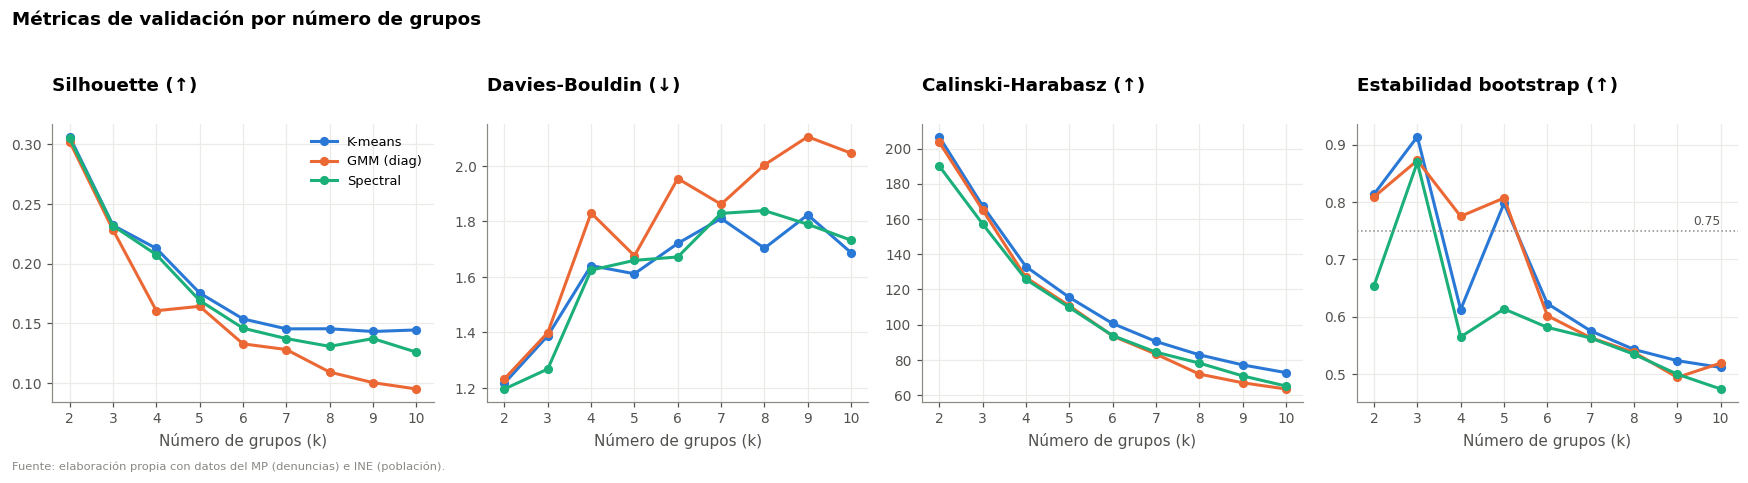

In [4]:
paneles = [("silhouette", "Silhouette (↑)"), ("davies_bouldin", "Davies-Bouldin (↓)"),
           ("calinski_harabasz", "Calinski-Harabasz (↑)"), ("estabilidad", "Estabilidad bootstrap (↑)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, (col, titulo) in zip(axes, paneles):
    for alg in ALGORITMOS:
        d = barrido[barrido["algoritmo"] == alg]
        ax.plot(d["k"], d[col], marker="o", markersize=5, color=COLOR_ALG[alg], label=alg)
    if col == "estabilidad":
        ax.axhline(UMBRAL_ESTABLE, color=COLOR["gris"], linestyle=":", linewidth=1)
        ax.text(10, UMBRAL_ESTABLE + 0.01, "0.75", ha="right", fontsize=8, color=COLOR["texto_sec"])
    ax.set_title(titulo)
    ax.set_xlabel("Número de grupos (k)")
    ax.set_xticks(list(RANGO_K))
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Métricas de validación por número de grupos", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "01_metricas_por_k", CARPETA_FIG)
plt.show()

## 2. Criterio propio de cada algoritmo

### 2.1 K-means: método del codo y estadístico gap

- **Codo:** la inercia (suma de distancias al cuadrado a los centroides) siempre baja al aumentar $k$. El "codo" es el punto a partir del cual agregar grupos deja de reducirla de forma notable. Se localiza como el punto de la curva más alejado de la recta que une sus extremos (método *kneedle*).
- **Gap** (Tibshirani et al., 2001): compara la inercia con la de datos **sin estructura** de referencia. Regla 1-SE: el menor $k$ con $\text{Gap}(k) \ge \text{Gap}(k+1) - s_{k+1}$.

In [5]:
inercias = np.array([KMeans(k, n_init=20, random_state=SEMILLA).fit(X).inertia_ for k in range(1, 11)])
ks = np.arange(1, 11)
xn = (ks - ks[0]) / (ks[-1] - ks[0])
yn = (inercias - inercias[-1]) / (inercias[0] - inercias[-1])
k_codo = int(ks[np.argmax(np.abs(yn - (1 - xn)))])

gap, s_gap, k_gap = estadistico_gap(X, k_max=10, n_ref=20, semilla=SEMILLA)
print(f"Codo (kneedle): k = {k_codo}")
print(f"Gap (regla 1-SE): k = {k_gap}")
display(pd.DataFrame({"inercia": inercias, "gap": gap, "s_k": s_gap}, index=pd.Index(ks, name="k")))

Codo (kneedle): k = 3
Gap (regla 1-SE): k = 1


,inercia,gap,s_k
k,,,
1,"3,400.000",0.858,0.029
2,"2,109.712",0.844,0.023
3,"1,704.768",0.921,0.019
4,"1,554.258",0.933,0.016
5,"1,428.853",0.930,0.014
6,"1,355.966",0.930,0.017
7,"1,292.579",0.938,0.014
8,"1,237.139",0.926,0.014
9,"1,186.576",0.936,0.017


### 2.2 GMM: BIC y certeza de la asignación

El GMM asigna a cada municipio una **probabilidad** de pertenecer a cada grupo. La **certeza** es la probabilidad máxima: si es cercana a 1, el municipio pertenece claramente a su grupo. Si está por debajo de 0.7, es un municipio **ambiguo** o de frontera.

In [6]:
filas_gmm = []
for k in range(1, 11):
    gmm = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=SEMILLA).fit(X)
    p = gmm.predict_proba(X).max(axis=1)
    filas_gmm.append({"k": k, "BIC": gmm.bic(X), "AIC": gmm.aic(X),
                      "certeza_media": p.mean(), "pct_ambiguos (<0.7)": (p < 0.7).mean() * 100})
gmm_k = pd.DataFrame(filas_gmm).set_index("k")
k_bic = int(gmm_k["BIC"].idxmin())
print(f"BIC mínimo: k = {k_bic}")
display(gmm_k)

BIC mínimo: k = 5


,BIC,AIC,certeza_media,pct_ambiguos (<0.7)
k,,,,
1,"9,765.361","9,688.782",1.000,0.000
2,"8,497.545","8,340.558",0.972,2.941
3,"7,999.910","7,762.515",0.964,4.706
4,"7,873.281","7,555.479",0.948,6.176
5,"7,837.233","7,439.023",0.947,7.059
6,"7,875.301","7,396.683",0.937,7.059
7,"7,906.584","7,347.558",0.934,8.235
8,"7,968.256","7,328.822",0.938,7.353
9,"8,010.883","7,291.042",0.923,9.706


### 2.3 Spectral: *eigengap*

Spectral clustering construye una red de 10 vecinos más cercanos y estudia los **autovalores de su laplaciano normalizado**. Si hay $k$ grupos bien definidos, los primeros $k$ autovalores son pequeños y después hay un **salto** (*eigengap*).

In [7]:
A = kneighbors_graph(X, n_neighbors=10, include_self=False)
A = 0.5 * (A + A.T)
autovalores = np.sort(np.linalg.eigvalsh(laplacian(A, normed=True).toarray()))[:11]
saltos = np.diff(autovalores)
k_eigengap = int(np.argmax(saltos[1:]) + 2)     # se ignora el salto trivial 1 -> 2
print(f"Mayor salto de autovalores: entre λ{k_eigengap} y λ{k_eigengap + 1}  ->  k = {k_eigengap}")
display(pd.DataFrame({"autovalor": autovalores[:10], "salto al siguiente": saltos[:10]},
                     index=pd.Index(range(1, 11), name="i")))

Mayor salto de autovalores: entre λ3 y λ4  ->  k = 3


,autovalor,salto al siguiente
i,,
1,0.000,0.029
2,0.029,0.038
3,0.068,0.089
4,0.157,0.011
5,0.167,0.020
6,0.187,0.026
7,0.213,0.012
8,0.225,0.034
9,0.259,0.007


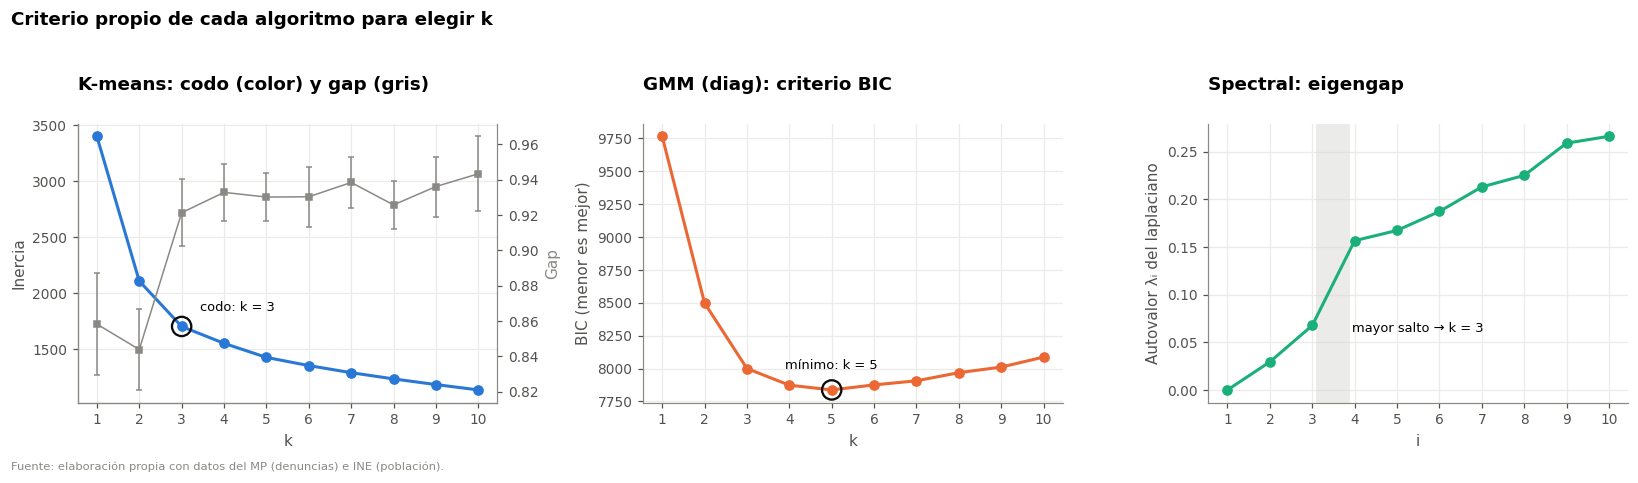

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
ax.plot(ks, inercias, marker="o", color=COLOR_ALG["K-means"])
ax.scatter([k_codo], [inercias[k_codo - 1]], s=160, facecolor="none", edgecolor=COLOR["texto"], linewidth=1.5, zorder=3)
ax.annotate(f"codo: k = {k_codo}", (k_codo, inercias[k_codo - 1]), xytext=(12, 10),
            textcoords="offset points", fontsize=8.5)
ax2 = ax.twinx()
ax2.errorbar(ks, gap, yerr=s_gap, color=COLOR["gris"], marker="s", markersize=4, linewidth=1, capsize=2)
ax2.set_ylabel("Gap", color=COLOR["gris"])
ax2.spines["right"].set_visible(True)
ax2.grid(False)
ax.set_xlabel("k"); ax.set_ylabel("Inercia")
ax.set_title("K-means: codo (color) y gap (gris)")

ax = axes[1]
ax.plot(gmm_k.index, gmm_k["BIC"], marker="o", color=COLOR_ALG["GMM (diag)"])
ax.scatter([k_bic], [gmm_k.loc[k_bic, "BIC"]], s=160, facecolor="none", edgecolor=COLOR["texto"], linewidth=1.5, zorder=3)
ax.annotate(f"mínimo: k = {k_bic}", (k_bic, gmm_k.loc[k_bic, "BIC"]), xytext=(0, 14),
            textcoords="offset points", ha="center", fontsize=8.5)
ax.set_xlabel("k"); ax.set_ylabel("BIC (menor es mejor)")
ax.set_title("GMM (diag): criterio BIC")

ax = axes[2]
ax.plot(range(1, 11), autovalores[:10], marker="o", color=COLOR_ALG["Spectral"])
ax.axvspan(k_eigengap + 0.1, k_eigengap + 0.9, color=COLOR["gris_claro"], alpha=0.5, lw=0)
ax.annotate(f"mayor salto → k = {k_eigengap}", (k_eigengap + 0.5, autovalores[k_eigengap - 1]),
            xytext=(12, -4), textcoords="offset points", fontsize=8.5)
ax.set_xlabel("i"); ax.set_ylabel("Autovalor λᵢ del laplaciano")
ax.set_title("Spectral: eigengap")
for a in axes:
    a.set_xticks(range(1, 11))
fig.suptitle("Criterio propio de cada algoritmo para elegir k", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "02_criterios_propios", CARPETA_FIG)
plt.show()

## 3. Elección de $k$ para cada algoritmo

**Regla común** (la misma para los tres algoritmos, basada en el umbral de estabilidad de Hennig): entre $k \ge 3$ (ver notebook 05), se elige el $k$ con **mayor Silhouette** entre los que tienen una partición **estable** (ARI bootstrap ≥ 0.75). Así no se premia una buena métrica obtenida con una partición que cambia al remuestrear.

In [9]:
elegibles = barrido[(barrido["k"] >= 3) & (barrido["estabilidad"] >= UMBRAL_ESTABLE)]
k_elegido = elegibles.loc[elegibles.groupby("algoritmo")["silhouette"].idxmax()].set_index("algoritmo")
k_elegido = k_elegido.reindex(ALGORITMOS)
criterios = pd.DataFrame({
    "k por regla común": k_elegido["k"],
    "criterio propio": {"K-means": f"codo {k_codo}; gap {k_gap}",
                        "GMM (diag)": f"BIC {k_bic}",
                        "Spectral": f"eigengap {k_eigengap}"},
    "k estables (≥ 3)": elegibles.groupby("algoritmo")["k"].apply(lambda s: ", ".join(map(str, s))),
})
display(criterios)
K_ELEGIDO = {alg: int(k) for alg, k in k_elegido["k"].items()}

,k por regla común,criterio propio,k estables (≥ 3)
GMM (diag),3,BIC 5,"3, 4, 5"
K-means,3,codo 3; gap 1,"3, 5"
Spectral,3,eigengap 3,3


## 4. Comparación de los tres modelos

In [10]:
etiquetas = {alg: ordenar_grupos(X, constructor(alg, K_ELEGIDO[alg])(X)) for alg in ALGORITMOS}

comparacion = k_elegido[["k", "silhouette", "davies_bouldin", "calinski_harabasz",
                         "estabilidad", "estabilidad_sd", "n_grupo_menor", "pct_grupo_mayor"]].copy()
comparacion["tamaños"] = [", ".join(str(n) for n in np.bincount(etiquetas[a])[1:]) for a in ALGORITMOS]
comparacion["pos_silhouette"] = comparacion["silhouette"].rank(ascending=False)
comparacion["pos_davies_bouldin"] = comparacion["davies_bouldin"].rank(ascending=True)
comparacion["pos_calinski"] = comparacion["calinski_harabasz"].rank(ascending=False)
comparacion["pos_estabilidad"] = comparacion["estabilidad"].rank(ascending=False)
comparacion["posición_media"] = comparacion.filter(like="pos_").mean(axis=1)
comparacion = comparacion.sort_values("posición_media")
display(comparacion)
GANADOR = comparacion.index[0]
print(f"Modelo con mejor desempeño global: {GANADOR} (k = {K_ELEGIDO[GANADOR]})")

,k,silhouette,davies_bouldin,calinski_harabasz,estabilidad,estabilidad_sd,n_grupo_menor,pct_grupo_mayor,tamaños,pos_silhouette,pos_davies_bouldin,pos_calinski,pos_estabilidad,posición_media
algoritmo,,,,,,,,,,,,,,
K-means,3,0.232,1.388,167.557,0.914,0.075,88,47.647,"90, 162, 88",1.000,2.000,1.000,1.000,1.250
Spectral,3,0.232,1.268,157.261,0.869,0.060,67,58.529,"74, 199, 67",2.000,1.000,3.000,3.000,2.250
GMM (diag),3,0.228,1.399,165.248,0.873,0.075,88,47.941,"88, 163, 89",3.000,3.000,2.000,2.000,2.500


Modelo con mejor desempeño global: K-means (k = 3)


### 4.1 Concordancia entre algoritmos

Si algoritmos con lógicas distintas producen particiones parecidas, la estructura encontrada es **robusta** y no un artefacto de un método particular.

In [11]:
concordancia = pd.DataFrame(
    [[adjusted_rand_score(etiquetas[a], etiquetas[b]) for b in ALGORITMOS] for a in ALGORITMOS],
    index=ALGORITMOS, columns=ALGORITMOS)
display(concordancia.round(2))

,K-means,GMM (diag),Spectral
K-means,1.000,0.880,0.680
GMM (diag),0.880,1.000,0.690
Spectral,0.680,0.690,1.000


### 4.2 Gráficos de silueta

Cada barra horizontal es un municipio. Barras largas hacia la derecha indican municipios bien asignados; barras negativas, municipios que estarían mejor en otro grupo.

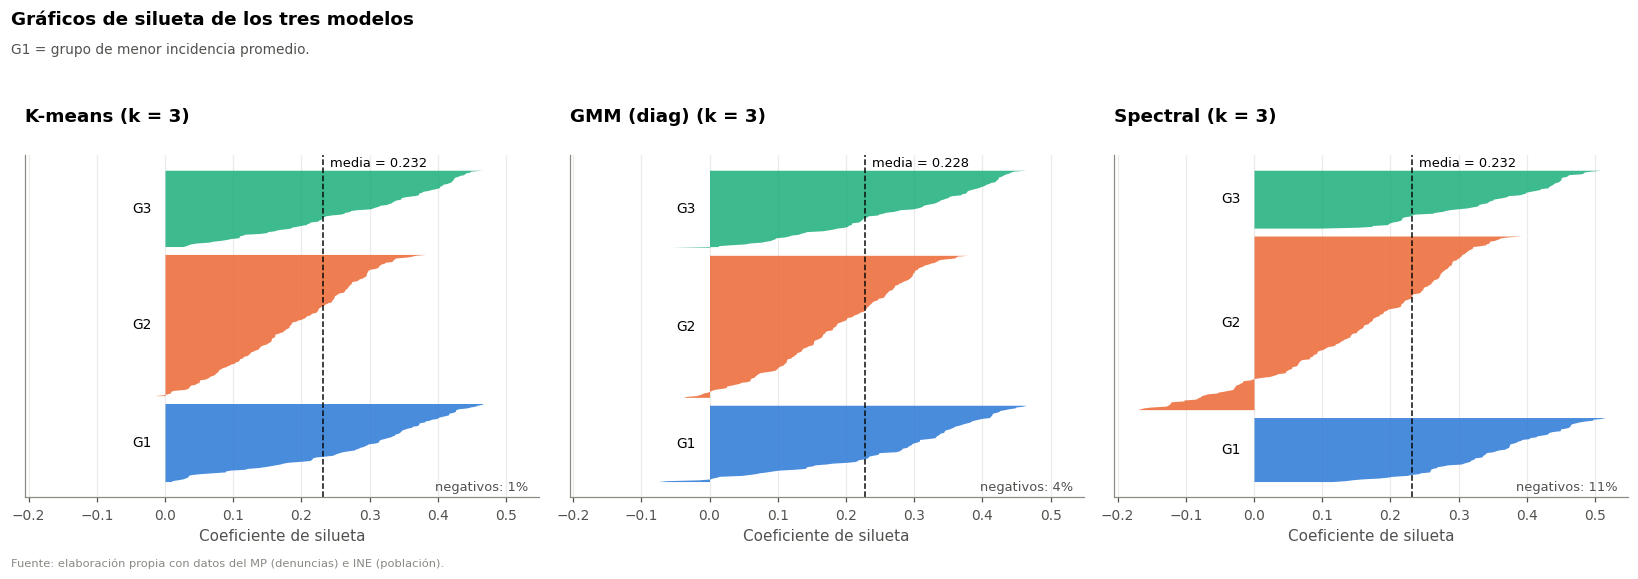

In [12]:
COLOR_GRUPO = [COLOR["azul"], COLOR["naranja"], COLOR["aqua"], COLOR["amarillo"],
               COLOR["magenta"], COLOR["verde"]]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharex=True)
for ax, alg in zip(axes, ALGORITMOS):
    lab = etiquetas[alg]
    sil = silhouette_samples(X, lab)
    y = 0
    for g in sorted(np.unique(lab)):
        v = np.sort(sil[lab == g])
        ax.fill_betweenx(np.arange(y, y + len(v)), 0, v, color=COLOR_GRUPO[g - 1], alpha=0.85, lw=0)
        ax.text(-0.02, y + len(v) / 2, f"G{g}", ha="right", va="center", fontsize=9)
        y += len(v) + 8
    media = sil.mean()
    ax.axvline(media, color=COLOR["texto"], linestyle="--", linewidth=1)
    ax.text(media + 0.01, y - 5, f"media = {media:.3f}", fontsize=8.5)
    ax.text(0.98, 0.02, f"negativos: {(sil < 0).mean():.0%}", transform=ax.transAxes,
            ha="right", fontsize=8.5, color=COLOR["texto_sec"])
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Coeficiente de silueta")
    ax.set_title(f"{alg} (k = {K_ELEGIDO[alg]})")
fig.suptitle("Gráficos de silueta de los tres modelos", x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.text(0.01, 0.905, "G1 = grupo de menor incidencia promedio.", fontsize=9, color=COLOR["texto_sec"])
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.9))
guardar_figura(fig, "03_siluetas", CARPETA_FIG)
plt.show()

### 4.3 Los grupos en el plano de las componentes principales

Proyección solo para **visualizar**: los modelos se ajustaron con las 10 variables.

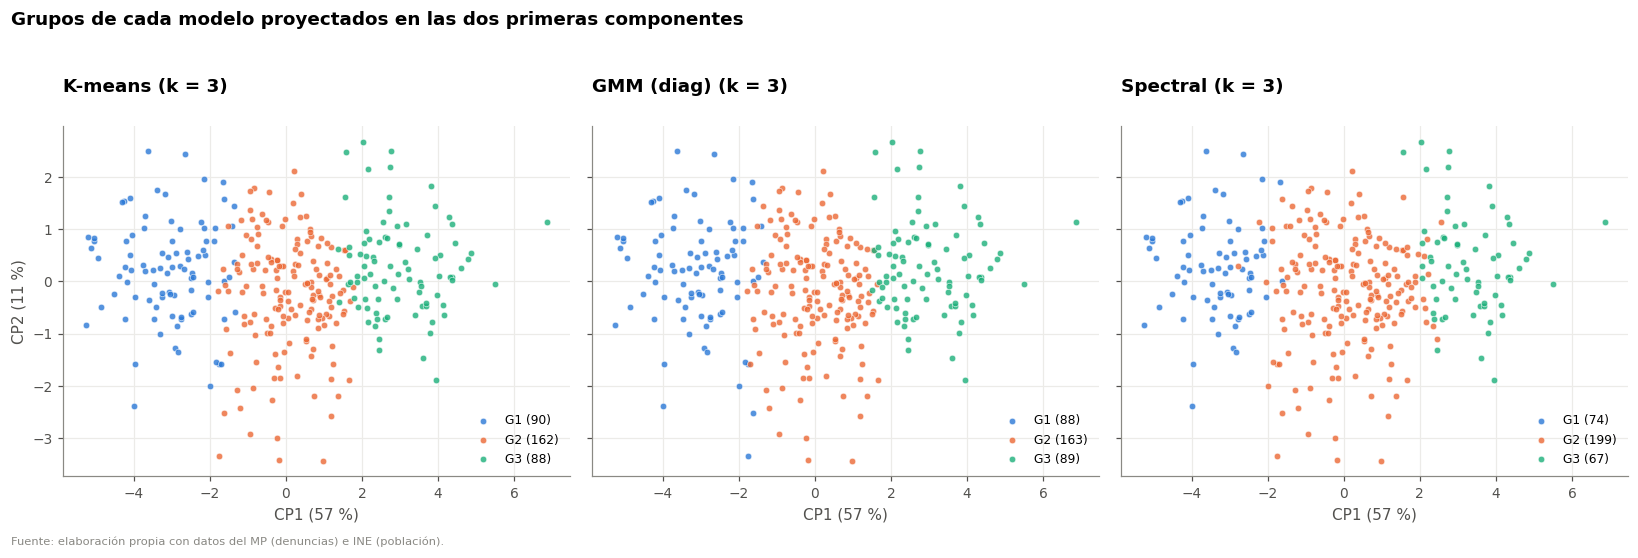

In [13]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
P = pca.transform(X)
var = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True)
for ax, alg in zip(axes, ALGORITMOS):
    lab = etiquetas[alg]
    for g in sorted(np.unique(lab)):
        ax.scatter(P[lab == g, 0], P[lab == g, 1], s=18, color=COLOR_GRUPO[g - 1], alpha=0.8,
                   edgecolor="white", linewidth=0.4, label=f"G{g} ({(lab == g).sum()})")
    ax.set_title(f"{alg} (k = {K_ELEGIDO[alg]})")
    ax.set_xlabel(f"CP1 ({var[0]:.0f} %)")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel(f"CP2 ({var[1]:.0f} %)")
fig.suptitle("Grupos de cada modelo proyectados en las dos primeras componentes", x=0.01,
             ha="left", fontweight="bold", fontsize=12)
fuente(fig, FUENTE)
fig.tight_layout(rect=(0, 0.02, 1, 0.95))
guardar_figura(fig, "04_grupos_pca", CARPETA_FIG)
plt.show()

## 5. Sensibilidad: comparación con $k = 5$

$k = 5$ es la segunda configuración estable para K-means y GMM. Ofrecería más detalle para la caracterización. Se compara el desempeño de los tres algoritmos con ese valor para saber si el ranking depende de $k$.

In [14]:
k5 = barrido[barrido["k"] == 5].set_index("algoritmo").reindex(ALGORITMOS)[
    ["silhouette", "davies_bouldin", "calinski_harabasz", "estabilidad", "n_grupo_menor"]]
display(k5)
print("Mejor algoritmo con k = 5 por Silhouette:", k5["silhouette"].idxmax(),
      "| por estabilidad:", k5["estabilidad"].idxmax())

,silhouette,davies_bouldin,calinski_harabasz,estabilidad,n_grupo_menor
algoritmo,,,,,
K-means,0.175,1.611,115.536,0.798,42
GMM (diag),0.164,1.676,110.765,0.807,40
Spectral,0.169,1.660,109.833,0.613,43


Mejor algoritmo con k = 5 por Silhouette: K-means | por estabilidad: GMM (diag)


## 6. Registro de resultados

In [15]:
salida = pd.DataFrame({f"grupo_{alg}": etiquetas[alg] for alg in ALGORITMOS}, index=X_df.index)
salida.to_csv(RUTA_REPORTES / "06_etiquetas_modelos.csv", encoding="utf-8-sig")

decisiones_06 = {
    "representacion": decisiones["representacion"],
    "k_por_algoritmo": K_ELEGIDO,
    "ganador": GANADOR,
    "k_ganador": K_ELEGIDO[GANADOR],
    "k_alternativo_para_optimizacion": 5,
    "semilla": SEMILLA,
}
with open(RUTA_REPORTES / "06_decisiones.json", "w", encoding="utf-8") as f:
    json.dump(decisiones_06, f, ensure_ascii=False, indent=2)
print(json.dumps(decisiones_06, ensure_ascii=False, indent=2))

{
  "representacion": "R4b_agravados_agrupados",
  "k_por_algoritmo": {
    "K-means": 3,
    "GMM (diag)": 3,
    "Spectral": 3
  },
  "ganador": "K-means",
  "k_ganador": 3,
  "k_alternativo_para_optimizacion": 5,
  "semilla": 42
}


## 7. Conclusiones

**Elección de $k$**

- Con la regla común (mayor Silhouette entre las particiones estables con $k \ge 3$), los **tres algoritmos eligen $k = 3$**, que además es la partición más estable de todas (ARI 0.87–0.91).
- Los criterios propios apuntan en la misma dirección: el **codo** de K-means y el **eigengap** de Spectral indican $k = 3$. El BIC del GMM prefiere $k = 5$, que es la segunda configuración estable de K-means y GMM y se explora en la optimización.
- El **estadístico gap** indica $k = 1$: frente a una referencia sin estructura, la mejora al separar grupos es modesta. Esto confirma lo visto en el EDA y en el notebook 05: los municipios forman un **continuo de incidencia** que se segmenta de forma útil y estable, no grupos naturalmente aislados. Conviene reportarlo como un hallazgo, no como un problema.

**Comparación de los modelos (objetivo específico 1)**

| | K-means | GMM (diag) | Spectral |
|---|---|---|---|
| Silhouette | **0.232** | 0.228 | **0.232** |
| Davies-Bouldin | 1.388 | 1.399 | **1.268** |
| Calinski-Harabasz | **167.6** | 165.2 | 157.3 |
| Estabilidad | **0.914** | 0.873 | 0.869 |
| Silueta negativa | **1 %** | 4 % | 11 % |

- **K-means es el modelo con mejor desempeño global**: primero en Silhouette (empatado), Calinski-Harabasz y estabilidad, y con solo el 1 % de municipios con silueta negativa.
- K-means y GMM coinciden mucho (ARI 0.88). Spectral asigna más municipios al grupo intermedio (199 frente a 162) y deja un 11 % de municipios mal ubicados.
- Con $k = 3$, los grupos se ordenan a lo largo de la **CP1 (intensidad delictiva general)**: baja, media y alta incidencia. La optimización (notebook 07) evaluará si $k = 5$ agrega **perfiles** más informativos (por ejemplo, patrimonial frente a violento) sin perder estabilidad.